In [1]:
# Import necessary libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn  as sns

# Display all columns
pd.set_option('display.max_columns', None)

# Set visualization style
sns.set_theme(style="whitegrid")

# Display plots within Jupyter Notebook
%matplotlib inline

In [2]:
# Load datasets
stolen_vehicle = pd.read_csv('stolen_vehicles.csv')
location = pd.read_csv('locations.csv')
make = pd.read_csv('make_details.csv')

# Check dataset dimensions
print("Stolen vehicle:", stolen_vehicle.shape)
print("Locations", location.shape)
print("Vehicle makes:", make.shape)

Stolen vehicle: (4553, 8)
Locations (16, 5)
Vehicle makes: (138, 3)


In [3]:
# Check the structure of each dataset
stolen_vehicle.info()
location.info()
make.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4553 entries, 0 to 4552
Data columns (total 8 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   vehicle_id    4553 non-null   int64  
 1   vehicle_type  4527 non-null   object 
 2   make_id       4538 non-null   float64
 3   model_year    4538 non-null   float64
 4   vehicle_desc  4520 non-null   object 
 5   color         4538 non-null   object 
 6   date_stolen   4553 non-null   object 
 7   location_id   4553 non-null   int64  
dtypes: float64(2), int64(2), object(4)
memory usage: 284.7+ KB
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 16 entries, 0 to 15
Data columns (total 5 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   location_id  16 non-null     int64  
 1   region       16 non-null     object 
 2   country      16 non-null     object 
 3   population   16 non-null     object 
 4   density      16 non-null     float64
dtyp

# Assessing the Stolen_vehicle dataset

In [4]:
# Read the first few lines of stolen_vehicles table
stolen_vehicle.head()

,vehicle_id,vehicle_type,make_id,model_year,vehicle_desc,color,date_stolen,location_id
0,1,Trailer,623.0,2021.0,BST2021D,Silver,11/5/21,102
1,2,Boat Trailer,623.0,2021.0,OUTBACK BOATS FT470,Silver,12/13/21,105
2,3,Boat Trailer,623.0,2021.0,ASD JETSKI,Silver,2/13/22,102
3,4,Trailer,623.0,2021.0,MSC 7X4,Silver,11/13/21,106
4,5,Trailer,623.0,2018.0,D-MAX 8X5,Silver,1/10/22,102


In [5]:
# Check complete duplicate records
stolen_vehicle.duplicated().sum()

np.int64(0)

In [6]:
# Check duplicate vehicle_IDs
stolen_vehicle['vehicle_id']. duplicated().sum()

np.int64(0)

In [7]:
# Check colums name
stolen_vehicle.columns

Index(['vehicle_id', 'vehicle_type', 'make_id', 'model_year', 'vehicle_desc',
       'color', 'date_stolen', 'location_id'],
      dtype='object')

In [8]:
# Vehicle_type distribution
stolen_vehicle['vehicle_type'].value_counts(dropna=False)

vehicle_type
Stationwagon               945
Saloon                     851
Hatchback                  644
Trailer                    582
Utility                    466
Roadbike                   297
Moped                      187
Light Van                  154
Boat Trailer               105
Trailer - Heavy             90
Caravan                     44
Other Truck                 42
Sports Car                  40
NaN                         26
Flat Deck Truck             17
Mobile Home - Light         15
Convertible                 12
Cab and Chassis Only         8
Heavy Van                    7
Light Bus                    6
All Terrain Vehicle          5
Tractor                      4
Trail Bike                   2
Mobile Machine               2
Special Purpose Vehicle      1
Articulated Truck            1
Name: count, dtype: int64

In [9]:
# Colour distribution
stolen_vehicle['color'].value_counts(dropna=False)

color
Silver    1272
White      934
Black      589
Blue       512
Red        390
Grey       378
Green      224
Gold        77
Brown       49
Yellow      39
Orange      35
Purple      26
NaN         15
Cream        9
Pink         4
Name: count, dtype: int64

In [10]:
# Percentage distribution of vehicle types
vehicle_type_percentage = (
    stolen_vehicle['vehicle_type']
    .value_counts(normalize=True, dropna=False)
    .mul(100)
    .round(2)
)
print(vehicle_type_percentage)

vehicle_type
Stationwagon               20.76
Saloon                     18.69
Hatchback                  14.14
Trailer                    12.78
Utility                    10.24
Roadbike                    6.52
Moped                       4.11
Light Van                   3.38
Boat Trailer                2.31
Trailer - Heavy             1.98
Caravan                     0.97
Other Truck                 0.92
Sports Car                  0.88
NaN                         0.57
Flat Deck Truck             0.37
Mobile Home - Light         0.33
Convertible                 0.26
Cab and Chassis Only        0.18
Heavy Van                   0.15
Light Bus                   0.13
All Terrain Vehicle         0.11
Tractor                     0.09
Trail Bike                  0.04
Mobile Machine              0.04
Special Purpose Vehicle     0.02
Articulated Truck           0.02
Name: proportion, dtype: float64


In [11]:
# Checking missing values
stolen_vehicle.isnull().sum()

vehicle_id       0
vehicle_type    26
make_id         15
model_year      15
vehicle_desc    33
color           15
date_stolen      0
location_id      0
dtype: int64

In [12]:
# Convert date_stolen to datetime
stolen_vehicle['date_stolen'] = pd.to_datetime(
    stolen_vehicle['date_stolen'],
    format='%m/%d/%y',
    errors='coerce'
)

In [13]:
stolen_vehicle['date_stolen'].dtype

dtype('<M8[ns]')

In [14]:
stolen_vehicle['date_stolen'].isnull().sum()

np.int64(0)

In [15]:
# Extract year
stolen_vehicle['year']=stolen_vehicle['date_stolen'].dt.year

# Extract month number
stolen_vehicle['month']=stolen_vehicle['date_stolen'].dt.month

# Extract month name
stolen_vehicle['month_name']=stolen_vehicle['date_stolen'].dt.month_name()

# Extract day
stolen_vehicle['day']=stolen_vehicle['date_stolen'].dt.day

# Extract day of the week
stolen_vehicle['day_of_week']=stolen_vehicle['date_stolen'].dt.day_name()

stolen_vehicle.head()

,vehicle_id,vehicle_type,make_id,model_year,vehicle_desc,color,date_stolen,location_id,year,month,month_name,day,day_of_week
0,1,Trailer,623.0,2021.0,BST2021D,Silver,2021-11-05,102,2021,11,November,5,Friday
1,2,Boat Trailer,623.0,2021.0,OUTBACK BOATS FT470,Silver,2021-12-13,105,2021,12,December,13,Monday
2,3,Boat Trailer,623.0,2021.0,ASD JETSKI,Silver,2022-02-13,102,2022,2,February,13,Sunday
3,4,Trailer,623.0,2021.0,MSC 7X4,Silver,2021-11-13,106,2021,11,November,13,Saturday
4,5,Trailer,623.0,2018.0,D-MAX 8X5,Silver,2022-01-10,102,2022,1,January,10,Monday


# Assessing the location dataset

In [16]:
# Read the first few lines of location table
location.head()

,location_id,region,country,population,density
0,101,Northland,New Zealand,"201,500",16.11
1,102,Auckland,New Zealand,"1,695,200",343.09
2,103,Waikato,New Zealand,"513,800",21.50
3,104,Bay of Plenty,New Zealand,"347,700",28.80
4,105,Gisborne,New Zealand,"52,100",6.21


In [17]:
location.duplicated().sum()

np.int64(0)

In [18]:
location.isnull().sum()

location_id    0
region         0
country        0
population     0
density        0
dtype: int64

In [19]:
location['region'].value_counts()

region
Northland             1
Auckland              1
Waikato               1
Bay of Plenty         1
Gisborne              1
Hawke's Bay           1
Taranaki              1
Manawatū-Whanganui    1
Wellington            1
Tasman                1
Nelson                1
Marlborough           1
West Coast            1
Canterbury            1
Otago                 1
Southland             1
Name: count, dtype: int64

In [20]:
location.dtypes

location_id      int64
region          object
country         object
population      object
density        float64
dtype: object

In [21]:
# changing population data type to numeric 
location['population']=location['population'].str.replace(',', '', regex=False)

location['population'] = pd.to_numeric(location['population'])

location.dtypes

location_id      int64
region          object
country         object
population       int64
density        float64
dtype: object

In [22]:
location.isnull().sum()

location_id    0
region         0
country        0
population     0
density        0
dtype: int64

In [23]:
location.head()

,location_id,region,country,population,density
0,101,Northland,New Zealand,201500,16.11
1,102,Auckland,New Zealand,1695200,343.09
2,103,Waikato,New Zealand,513800,21.50
3,104,Bay of Plenty,New Zealand,347700,28.80
4,105,Gisborne,New Zealand,52100,6.21


In [24]:
# Check duplicate location IDs
location['location_id'].duplicated().sum()

np.int64(0)

# Assessing the vehicle make dataset

In [25]:
# Read the first few lines of make table
make.head()

,make_id,make_name,make_type
0,501,Aakron Xpress,Standard
1,502,ADLY,Standard
2,503,Alpha,Standard
3,504,Anglo,Standard
4,505,Aprilia,Standard


In [26]:
make.duplicated().sum()

np.int64(0)

In [27]:
make.isna().sum()

make_id      0
make_name    0
make_type    0
dtype: int64

In [28]:
make.columns

Index(['make_id', 'make_name', 'make_type'], dtype='object')

In [29]:
make.dtypes

make_id       int64
make_name    object
make_type    object
dtype: object

In [30]:
make['make_type'].value_counts()

make_type
Standard    123
Luxury       15
Name: count, dtype: int64

In [31]:
# Check duplicate make IDs
make['make_id'].duplicated().sum()

np.int64(0)

In [32]:
# Check unique vehicle manufacturers
make['make_name'].nunique()

138

# Combining the three dataset

In [33]:
# Merge stolen vehicle data with location data
merge_data = stolen_vehicle.merge(
    location,
    on='location_id',
    how='left',
validate='many_to_one',
indicator='location_match'
)

# Check location matching
print(merge_data['location_match'].value_counts())

location_match
both          4553
left_only        0
right_only       0
Name: count, dtype: int64


In [34]:
# Mergem with vehicle make details
merge_data = merge_data.merge(
    make,
    on='make_id',
    how='left',
    validate='many_to_one',
indicator='make_match'
)

# Check make matching
print(merge_data['make_match'].value_counts())

make_match
both          4538
left_only       15
right_only       0
Name: count, dtype: int64


In [35]:
# Check merged dataset dimensions
print(merge_data.shape)

(4553, 21)


In [36]:
# Check first five records
merge_data.head()

,vehicle_id,vehicle_type,make_id,model_year,vehicle_desc,color,date_stolen,location_id,year,month,month_name,day,day_of_week,region,country,population,density,location_match,make_name,make_type,make_match
0,1,Trailer,623.0,2021.0,BST2021D,Silver,2021-11-05,102,2021,11,November,5,Friday,Auckland,New Zealand,1695200,343.09,both,Trailer,Standard,both
1,2,Boat Trailer,623.0,2021.0,OUTBACK BOATS FT470,Silver,2021-12-13,105,2021,12,December,13,Monday,Gisborne,New Zealand,52100,6.21,both,Trailer,Standard,both
2,3,Boat Trailer,623.0,2021.0,ASD JETSKI,Silver,2022-02-13,102,2022,2,February,13,Sunday,Auckland,New Zealand,1695200,343.09,both,Trailer,Standard,both
3,4,Trailer,623.0,2021.0,MSC 7X4,Silver,2021-11-13,106,2021,11,November,13,Saturday,Hawke's Bay,New Zealand,182700,12.92,both,Trailer,Standard,both
4,5,Trailer,623.0,2018.0,D-MAX 8X5,Silver,2022-01-10,102,2022,1,January,10,Monday,Auckland,New Zealand,1695200,343.09,both,Trailer,Standard,both


In [37]:
merge_data.isna().sum()

vehicle_id         0
vehicle_type      26
make_id           15
model_year        15
vehicle_desc      33
color             15
date_stolen        0
location_id        0
year               0
month              0
month_name         0
day                0
day_of_week        0
region             0
country            0
population         0
density            0
location_match     0
make_name         15
make_type         15
make_match         0
dtype: int64

In [38]:
# Handling categorical missing values
categorical_columns=[
    'vehicle_type',
    'vehicle_desc',
    'color',
    'make_name',
    'make_type'
]

merge_data[categorical_columns]=(
    merge_data[categorical_columns]
    .fillna('Unknown')
)

In [39]:
# Handling numerical missing values
merge_data['make_id']=pd.to_numeric(
    merge_data['make_id'],
    errors='coerce'
)

merge_data['model_year']=pd.to_numeric(
    merge_data['model_year'],
    errors='coerce'
)

In [40]:
merge_data.isnull().sum()

vehicle_id         0
vehicle_type       0
make_id           15
model_year        15
vehicle_desc       0
color              0
date_stolen        0
location_id        0
year               0
month              0
month_name         0
day                0
day_of_week        0
region             0
country            0
population         0
density            0
location_match     0
make_name          0
make_type          0
make_match         0
dtype: int64

In [41]:
merge_data.dtypes

vehicle_id                 int64
vehicle_type              object
make_id                  float64
model_year               float64
vehicle_desc              object
color                     object
date_stolen       datetime64[ns]
location_id                int64
year                       int32
month                      int32
month_name                object
day                        int32
day_of_week               object
region                    object
country                   object
population                 int64
density                  float64
location_match          category
make_name                 object
make_type                 object
make_match              category
dtype: object

In [42]:
merge_data.shape

(4553, 21)

In [43]:
merge_data.head()

,vehicle_id,vehicle_type,make_id,model_year,vehicle_desc,color,date_stolen,location_id,year,month,month_name,day,day_of_week,region,country,population,density,location_match,make_name,make_type,make_match
0,1,Trailer,623.0,2021.0,BST2021D,Silver,2021-11-05,102,2021,11,November,5,Friday,Auckland,New Zealand,1695200,343.09,both,Trailer,Standard,both
1,2,Boat Trailer,623.0,2021.0,OUTBACK BOATS FT470,Silver,2021-12-13,105,2021,12,December,13,Monday,Gisborne,New Zealand,52100,6.21,both,Trailer,Standard,both
2,3,Boat Trailer,623.0,2021.0,ASD JETSKI,Silver,2022-02-13,102,2022,2,February,13,Sunday,Auckland,New Zealand,1695200,343.09,both,Trailer,Standard,both
3,4,Trailer,623.0,2021.0,MSC 7X4,Silver,2021-11-13,106,2021,11,November,13,Saturday,Hawke's Bay,New Zealand,182700,12.92,both,Trailer,Standard,both
4,5,Trailer,623.0,2018.0,D-MAX 8X5,Silver,2022-01-10,102,2022,1,January,10,Monday,Auckland,New Zealand,1695200,343.09,both,Trailer,Standard,both


In [44]:
# Remove the merge validation
merge_data.drop(columns=['location_match',
                       'make_match'], inplace=True)

# Exploratory Data Analysis

In [45]:
# check the country
merge_data['country'].unique()

array(['New Zealand'], dtype=object)

In [46]:
# Calculate total population across locations
total_population=location['population'].sum()

print("Total_population:", total_population)

Total_population: 5123200


In [47]:
# Calculate total vehicle across locations
total_vehicle=stolen_vehicle['vehicle_id'].nunique()
print("Total_vehicle:", total_vehicle)

Total_vehicle: 4553


In [48]:
# Calculate each regional population
regional_population=location[
    ['region','population','density']
].copy()

# Sort from highest to lowest
regional_population= regional_population.sort_values(
    'population',
    ascending=False
)

print(regional_population)

                region  population  density
1             Auckland     1695200   343.09
13          Canterbury      655000    14.72
8           Wellington      543500    67.52
2              Waikato      513800    21.50
3        Bay of Plenty      347700    28.80
7   Manawatū-Whanganui      258200    11.62
14               Otago      246000     7.89
0            Northland      201500    16.11
5          Hawke's Bay      182700    12.92
6             Taranaki      127300    17.55
15           Southland      102400     3.28
9               Tasman       58700     6.10
10              Nelson       54500   129.15
4             Gisborne       52100     6.21
11         Marlborough       51900     4.94
12          West Coast       32700     1.41


In [49]:
# identify regions with the highest vehicle theft
regional_theft=merge_data.groupby(
    'region',
    as_index=False
).agg(
    total_stolen=('vehicle_id','nunique')
)

# Sort from highest to lowest
regional_theft= regional_theft.sort_values(
    'total_stolen',
    ascending=False
)

print(regional_theft)

                region  total_stolen
0             Auckland          1638
2           Canterbury           660
1        Bay of Plenty           446
12          Wellington           420
11             Waikato           371
7            Northland           234
3             Gisborne           176
8                Otago           139
5   Manawatū-Whanganui           139
10            Taranaki           112
4          Hawke's Bay           100
6               Nelson            92
9            Southland            26


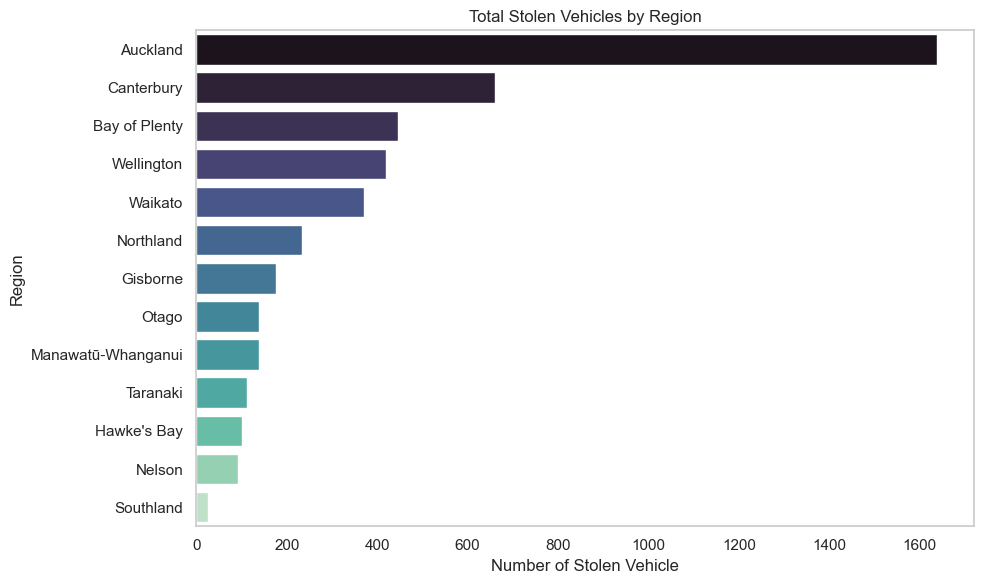

In [50]:
plt.figure(figsize=(10,6))
sns.barplot(
    data=regional_theft,
    x='total_stolen',
    y='region',
    palette='mako',
    hue='region',
    legend=False
)

plt.title('Total Stolen Vehicles by Region')
plt.xlabel('Number of Stolen Vehicle')
plt.ylabel('Region')

plt.grid(False)
plt.tight_layout()
plt.show()

In [51]:
# Combine regional theft and population
regional_analysis=regional_theft.merge(
    regional_population,
    on='region',
    how='left',
    validate='one_to_one'
)

In [52]:
# Calculate theft  rate per 100,000 residents
regional_analysis['theft_rate_per_100,000']=(
    regional_analysis['total_stolen']/
    regional_analysis['population']
) * 100000

regional_analysis['theft_rate_per_100,000']=(
    regional_analysis['theft_rate_per_100,000'].round(2)
)

# Sort by theft rate
regional_analysis = regional_analysis.sort_values(
    'theft_rate_per_100,000',
    ascending=False
)

print(regional_analysis)

                region  total_stolen  population  density  \
6             Gisborne           176       52100     6.21   
11              Nelson            92       54500   129.15   
2        Bay of Plenty           446      347700    28.80   
5            Northland           234      201500    16.11   
1           Canterbury           660      655000    14.72   
0             Auckland          1638     1695200   343.09   
9             Taranaki           112      127300    17.55   
3           Wellington           420      543500    67.52   
4              Waikato           371      513800    21.50   
7                Otago           139      246000     7.89   
10         Hawke's Bay           100      182700    12.92   
8   Manawatū-Whanganui           139      258200    11.62   
12           Southland            26      102400     3.28   

    theft_rate_per_100,000  
6                   337.81  
11                  168.81  
2                   128.27  
5                   116.13  


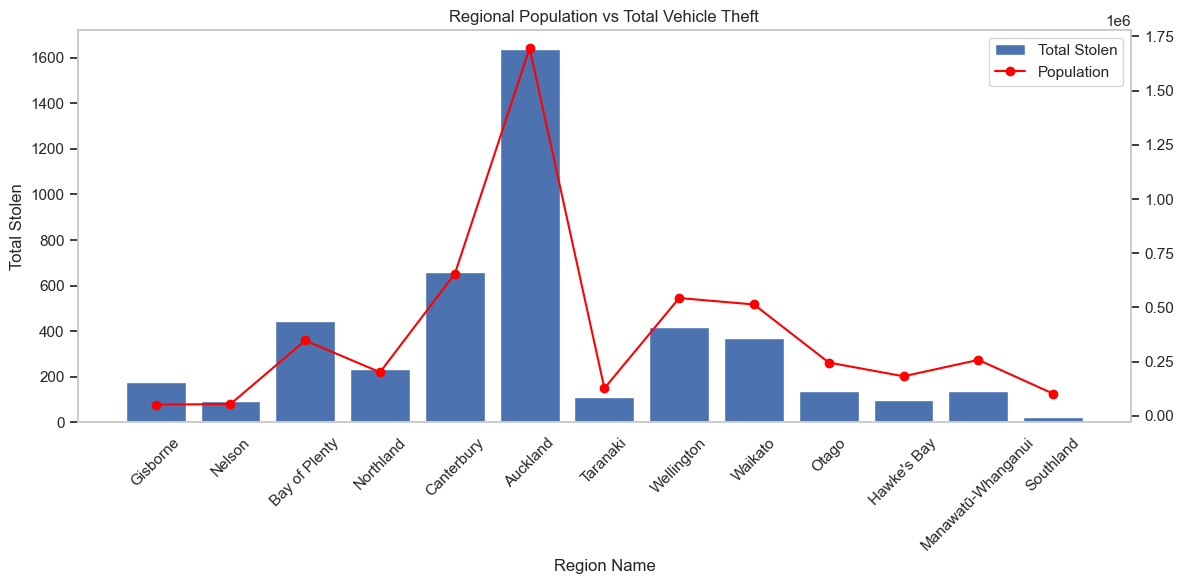

In [53]:
fig, ax1 = plt.subplots(figsize=(12, 6))

ax1.bar(
    regional_analysis['region'],
    regional_analysis['total_stolen'],
    label='Total Stolen'
)

ax1.set_xlabel('Region Name')
ax1.set_ylabel('Total Stolen')
ax1.grid(False)

ax2 = ax1.twinx()

ax2.plot(
    regional_analysis['region'],
    regional_analysis['population'],
    color='red',
    marker='o',
    label='Population'
)

ax2.grid(False)

ax1.set_title('Regional Population vs Total Vehicle Theft')
ax1.tick_params(axis='x', rotation=45)

lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()

ax1.legend(lines1 + lines2, labels1 + labels2)

plt.tight_layout()
plt.show()

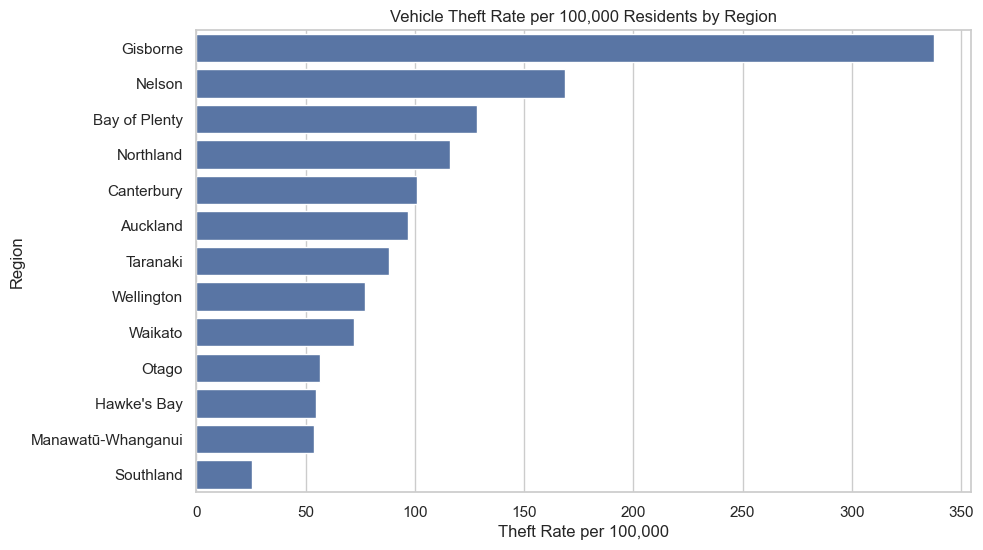

<Figure size 1000x600 with 0 Axes>

In [54]:
plt.figure(figsize=(10,6))
sns.barplot(
    data=regional_analysis,
    x='theft_rate_per_100,000',
    y='region'
)

plt.title('Vehicle Theft Rate per 100,000 Residents by Region')
plt.xlabel('Theft Rate per 100,000')
plt.ylabel('Region')

plt.figure(figsize=(10,6))
plt.show()

In [55]:
# Monthyl theft analysis
monthly_trend=merge_data.groupby(
    ['year','month','month_name'],
    as_index=False
).agg(
    total_stolen=('vehicle_id','nunique')
)

monthly_trend= monthly_trend.sort_values(
    ['year','month']
)

monthly_trend.head()

,year,month,month_name,total_stolen
0,2021,10,October,464
1,2021,11,November,560
2,2021,12,December,644
3,2022,1,January,740
4,2022,2,February,763


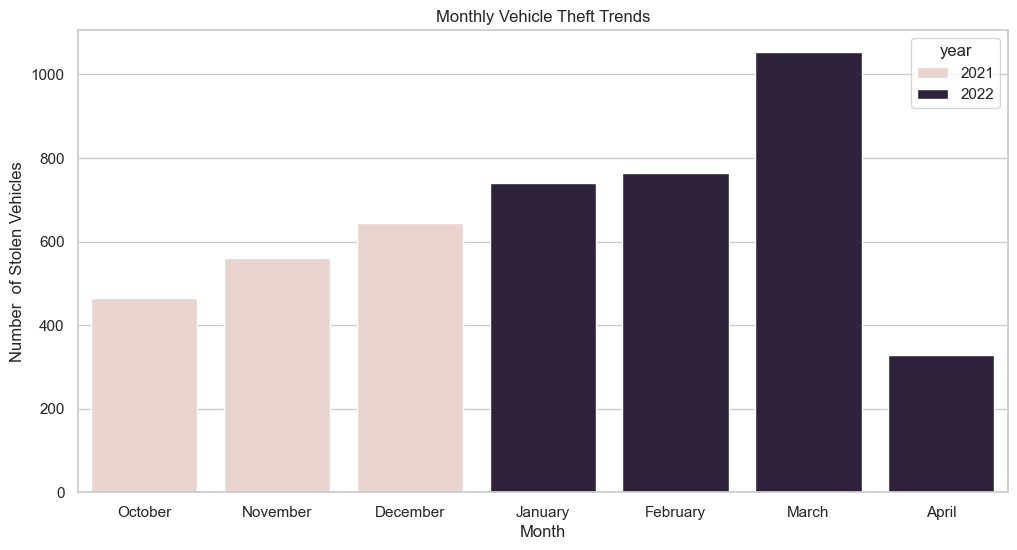

In [56]:
plt.figure(figsize=(12,6))

sns.barplot(
    data=monthly_trend,
    x='month_name',
    y='total_stolen',
    hue='year'
)

plt.title('Monthly Vehicle Theft Trends')
plt.xlabel('Month')
plt.ylabel('Number  of Stolen Vehicles')
plt.show()

In [57]:
# Calculate the number of observed days per month
monthly_days = (
    merge_data.groupby(['year', 'month'])['date_stolen']
    .nunique()
    .reset_index(name='days_observed')
)

# Merge with monthly theft totals
monthly_trend = monthly_trend.merge(
    monthly_days,
    on=['year', 'month'],
    how='left'
)

# Calculate average daily theft
monthly_trend['average_daily_theft'] = (
    monthly_trend['total_stolen'] /
    monthly_trend['days_observed']
).round(2)

print(monthly_trend)

   year  month month_name  total_stolen  days_observed  average_daily_theft
0  2021     10    October           464             25                18.56
1  2021     11   November           560             30                18.67
2  2021     12   December           644             31                20.77
3  2022      1    January           740             31                23.87
4  2022      2   February           763             28                27.25
5  2022      3      March          1053             31                33.97
6  2022      4      April           329              6                54.83


In [58]:
# Count stolen vehicles by weekday
weekday_theft = merge_data.groupby(
    'day_of_week'
).agg(
    total_stolen=('vehicle_id', 'nunique')
)

# Count the number of observed dates for each weekday
weekday_days = (
    merge_data.groupby('day_of_week')['date_stolen']
    .nunique()
)

weekday_theft['days_observed'] = weekday_days

# Calculate average daily theft for each weekday
weekday_theft['average_daily_theft'] = (
    weekday_theft['total_stolen'] /
    weekday_theft['days_observed']
).round(2)

# Sort by average daily theft
weekday_theft = weekday_theft.sort_values(
    'average_daily_theft',
    ascending=False
)

print(weekday_theft)

             total_stolen  days_observed  average_daily_theft
day_of_week                                                  
Monday                767             26                29.50
Tuesday               711             26                27.35
Friday                655             26                25.19
Wednesday             629             26                24.19
Thursday              619             26                23.81
Sunday                595             26                22.88
Saturday              577             26                22.19


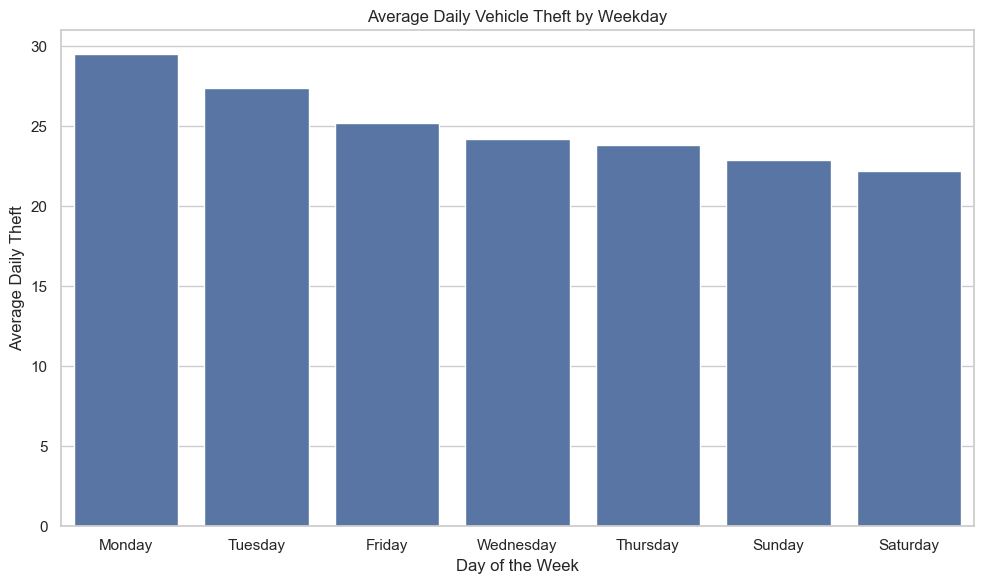

In [59]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=weekday_theft.reset_index(),
    x='day_of_week',
    y='average_daily_theft'
)

plt.title('Average Daily Vehicle Theft by Weekday')
plt.xlabel('Day of the Week')
plt.ylabel('Average Daily Theft')

plt.tight_layout()
plt.show()

In [60]:
# Analyse stolen vehicles by make_name
make_name = merge_data.groupby(
    'make_name',
    as_index=False
).agg(
    total_stolen=('vehicle_id', 'nunique')
)

# Select the five most stolen vehicle makes
top_5_makes = make_name.nlargest(
    5,
    'total_stolen'
)

print(top_5_makes)

    make_name  total_stolen
118    Toyota           716
122   Trailer           543
86     Nissan           482
76      Mazda           433
40       Ford           312


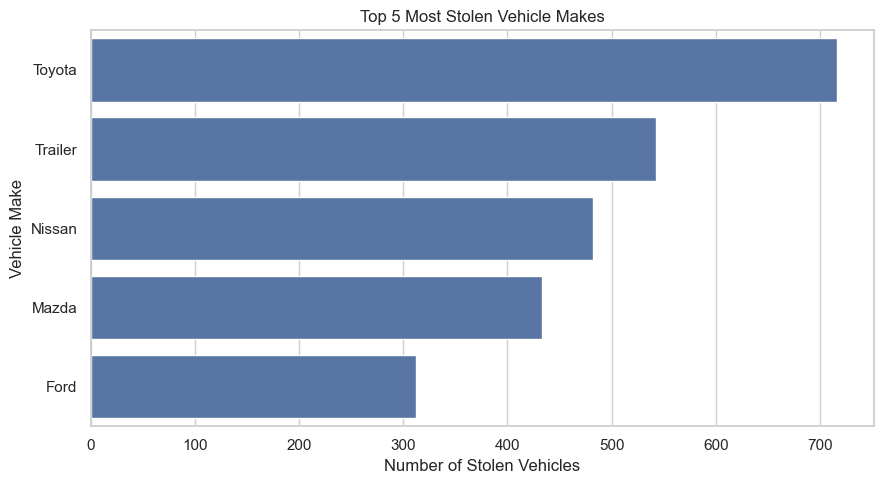

In [61]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=top_5_makes,
    x='total_stolen',
    y='make_name'
)

plt.title('Top 5 Most Stolen Vehicle Makes')
plt.xlabel('Number of Stolen Vehicles')
plt.ylabel('Vehicle Make')

plt.tight_layout()
plt.show()

In [62]:
# Analyse stolen vehicles by make_type
make_type = merge_data.groupby(
    'make_type',
    as_index=False
).agg(
    total_stolen=('vehicle_id', 'nunique')
)
print(make_type)

  make_type  total_stolen
0    Luxury           190
1  Standard          4348
2   Unknown            15


In [63]:
# Analyse vehicle types
vehicle_type_analysis = merge_data.groupby(
    'vehicle_type',
    as_index=False
).agg(
    total_stolen=('vehicle_id', 'nunique')
)

# Sort from highest to lowest
vehicle_type_analysis = vehicle_type_analysis.sort_values(
    'total_stolen',
    ascending=False
)

# Select top 10 vehicle types
top_10_vehicle_types = vehicle_type_analysis.head(10)

print(top_10_vehicle_types)

       vehicle_type  total_stolen
19     Stationwagon           945
16           Saloon           851
7         Hatchback           644
22          Trailer           582
25          Utility           466
15         Roadbike           297
13            Moped           187
10        Light Van           154
2      Boat Trailer           105
23  Trailer - Heavy            90


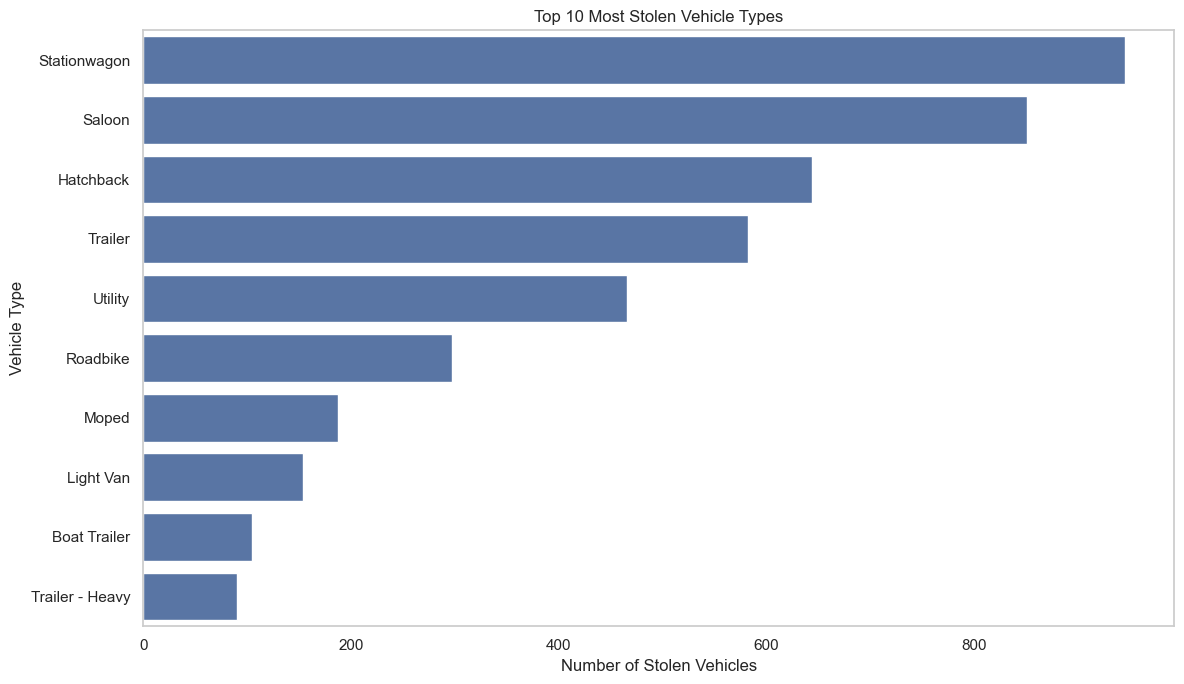

In [64]:
plt.figure(figsize=(12, 7))

sns.barplot(
    data=top_10_vehicle_types,
    x='total_stolen',
    y='vehicle_type'
)

plt.title('Top 10 Most Stolen Vehicle Types')
plt.xlabel('Number of Stolen Vehicles')
plt.ylabel('Vehicle Type')

plt.grid(False)
plt.tight_layout()
plt.show()

In [65]:
# Vehicle theft by model year

model_year_analysis = merge_data.groupby(
    'model_year',
    as_index=False
).agg(
    total_stolen=('vehicle_id', 'nunique')
)

model_year_analysis = model_year_analysis.sort_values(
    'total_stolen',
    ascending=False
)

print(model_year_analysis.head(10))

    model_year  total_stolen
45      2005.0           347
46      2006.0           333
47      2007.0           251
44      2004.0           238
48      2008.0           190
42      2002.0           181
43      2003.0           173
38      1998.0           159
36      1996.0           156
41      2001.0           152


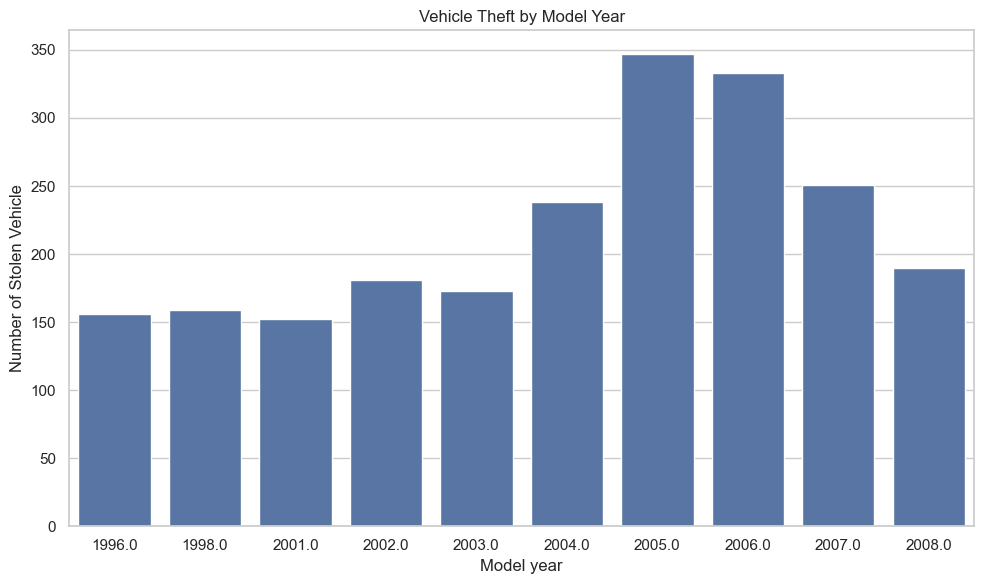

In [66]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=model_year_analysis.head(10),
    x='model_year',
    y='total_stolen'
)

plt.title('Vehicle Theft by Model Year')
plt.xlabel('Model year')
plt.ylabel('Number of Stolen Vehicle')

plt.tight_layout()
plt.show()

In [67]:
# Vehicle theft by colour
color_analysis = merge_data.groupby(
    'color',
    as_index=False
).agg(
    total_stolen=('vehicle_id', 'nunique')
)

top_5_colors = color_analysis.nlargest(
    5,
    'total_stolen'
)

print(top_5_colors)

     color  total_stolen
11  Silver          1272
13   White           934
0    Black           589
1     Blue           512
10     Red           390


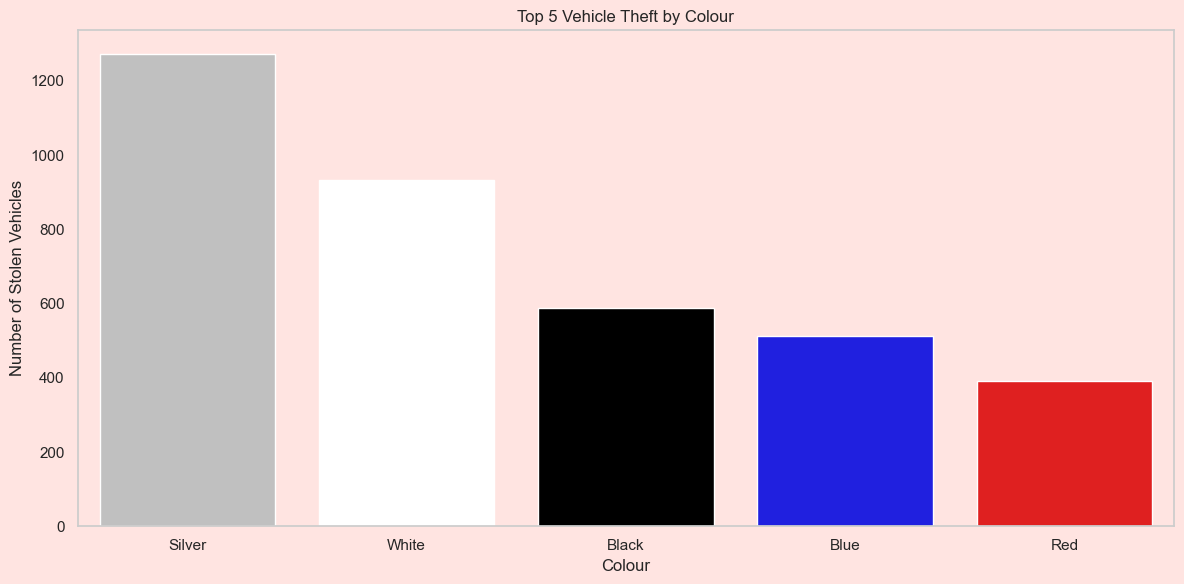

In [68]:
plt.figure(figsize=(12,6), facecolor='mistyrose')

ax = sns.barplot(
    data=top_5_colors,
    x='color',
    y='total_stolen',
    hue='color',
    palette={
        'Silver': 'silver',
        'White': 'white',
        'Black': 'black',
        'Blue': 'blue',
        'Red': 'red',
    },
    legend=False
)

ax.set_facecolor('mistyrose')

plt.title('Top 5 Vehicle Theft by Colour')
plt.xlabel('Colour')
plt.ylabel('Number of Stolen Vehicles')

plt.grid(False)
plt.tight_layout()
plt.show()

In [69]:
# Calculate the inclusive observation period
total_days = (
    merge_data['date_stolen'].max() -
    merge_data['date_stolen'].min()
).days + 1

print("Total observation days:", total_days)

Total observation days: 182


In [70]:
print("First recorded date:",
      merge_data['date_stolen'].min())

print("Last recorded date:",
      merge_data['date_stolen'].max())

First recorded date: 2021-10-07 00:00:00
Last recorded date: 2022-04-06 00:00:00
